# Tuần 7 - Tối ưu hóa mạng học sâu
Bài thực hành theo sách *Deep Learning with PyTorch*, chương 13 đến 23.

In [1]:
import os, copy, pickle, pprint
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(42)
np.random.seed(42)
os.makedirs("out", exist_ok=True)
print(torch.__version__)

2.14.0+cu130


## Chương 13 - Lưu và nạp model

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
X = torch.tensor(iris["data"], dtype=torch.float32)
y = torch.tensor(iris["target"], dtype=torch.long)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, shuffle=True)


class Multiclass(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(4, 8)
        self.act = nn.ReLU()
        self.output = nn.Linear(8, 3)
        self.logsoftmax = nn.LogSoftmax(dim=1)

    def forward(self, x):
        x = self.act(self.hidden(x))
        return self.logsoftmax(self.output(x))


model = Multiclass()
loss_fn = nn.NLLLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

n_epochs = 100
batch_size = 5
batch_start = torch.arange(0, len(X_train), batch_size)

for epoch in range(n_epochs):
    for start in batch_start:
        xb = X_train[start:start + batch_size]
        yb = y_train[start:start + batch_size]
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

with torch.no_grad():
    acc = (model(X_test).argmax(1) == y_test).float().mean()
print("Accuracy: %.2f" % acc)

Accuracy: 0.98


In [3]:
# copy tham số sang model mới
newmodel = Multiclass()
with torch.no_grad():
    for p_new, p_old in zip(newmodel.parameters(), model.parameters()):
        p_new.copy_(p_old)

with torch.no_grad():
    print("Accuracy: %.2f" % (newmodel(X_test).argmax(1) == y_test).float().mean())

Accuracy: 0.98


In [4]:
pp = pprint.PrettyPrinter(indent=4)
pp.pprint(model.state_dict())

OrderedDict([   (   'hidden.weight',
                    tensor([[ 0.6026,  0.2308,  0.5328,  1.0789],
        [-0.1096,  0.1009, -0.2434,  0.2936],
        [ 0.2831, -0.5960,  0.6655,  0.6642],
        [ 0.3615,  0.2880, -0.2509, -0.8020],
        [ 0.5980,  0.6415, -0.8109, -0.7803],
        [-0.2304, -0.0586, -0.2031,  0.3317],
        [-0.3947, -0.2305, -0.1412, -0.3006],
        [ 0.0012, -0.5386,  0.3962, -0.4823]])),
                (   'hidden.bias',
                    tensor([ 0.5104,  0.0832, -0.5506,  0.5467,  0.5310,  0.4040,  0.0547, -0.1934])),
                (   'output.weight',
                    tensor([[-0.1540, -0.0959, -0.4474,  0.3925,  0.9960, -0.1546,  0.2041,  0.0049],
        [ 0.3354, -0.2155, -0.0946,  0.1255, -0.1714,  0.2901,  0.1018,  0.1620],
        [ 0.2172, -0.0062,  0.7406, -0.5916, -1.4246, -0.2413,  0.1090, -0.0617]])),
                ('output.bias', tensor([ 0.1418,  0.1980, -0.0315]))])


In [5]:
# lưu bằng pickle
with open("out/iris-model.pickle", "wb") as fp:
    pickle.dump(model.state_dict(), fp)

m1 = Multiclass()
with open("out/iris-model.pickle", "rb") as fp:
    m1.load_state_dict(pickle.load(fp))

# lưu bằng torch.save (cách nên dùng)
torch.save(model.state_dict(), "out/iris-model.pth")
m2 = Multiclass()
m2.load_state_dict(torch.load("out/iris-model.pth"))

# lưu cả model
torch.save(model, "out/iris-model-full.pth")
m3 = torch.load("out/iris-model-full.pth", weights_only=False)

with torch.no_grad():
    for name, m in [("pickle", m1), ("state_dict", m2), ("full model", m3)]:
        print(name, "-> acc %.2f" % (m(X_test).argmax(1) == y_test).float().mean())

pickle -> acc 0.98
state_dict -> acc 0.98
full model -> acc 0.98


## Chương 14 - Hàm kích hoạt

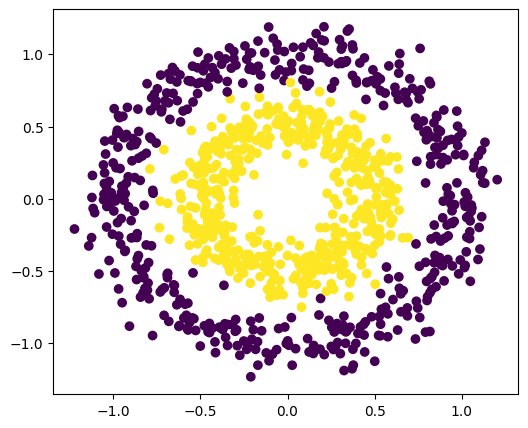

In [6]:
from sklearn.datasets import make_circles

Xc, yc = make_circles(n_samples=1000, factor=0.5, noise=0.1)
Xc = torch.tensor(Xc, dtype=torch.float32)
yc = torch.tensor(yc.reshape(-1, 1), dtype=torch.float32)

plt.figure(figsize=(6, 5))
plt.scatter(Xc[:, 0], Xc[:, 1], c=yc)
plt.show()

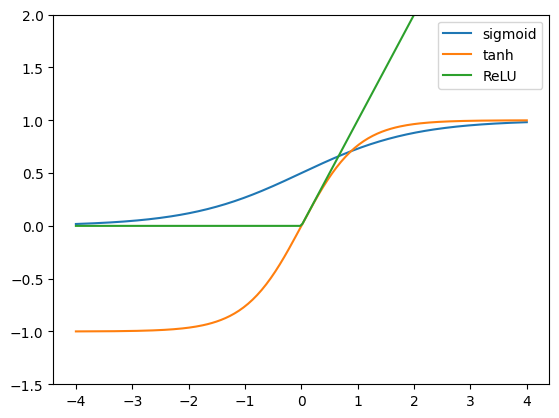

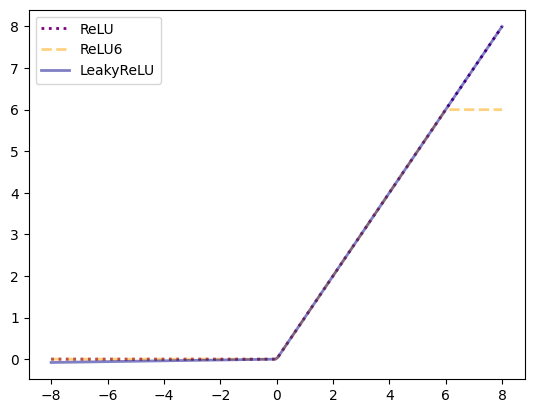

In [7]:
x = torch.linspace(-4, 4, 200)
plt.plot(x, nn.Sigmoid()(x), label="sigmoid")
plt.plot(x, nn.Tanh()(x), label="tanh")
plt.plot(x, nn.ReLU()(x), label="ReLU")
plt.ylim(-1.5, 2)
plt.legend()
plt.show()

x = torch.linspace(-8, 8, 200)
plt.plot(x, nn.ReLU()(x), c="purple", lw=2, ls=":", label="ReLU")
plt.plot(x, nn.ReLU6()(x), c="orange", lw=2, ls="--", alpha=0.5, label="ReLU6")
plt.plot(x, nn.LeakyReLU()(x), c="darkblue", lw=2, alpha=0.5, label="LeakyReLU")
plt.legend()
plt.show()

In [8]:
class CircleModel(nn.Module):
    def __init__(self, activation=nn.ReLU):
        super().__init__()
        self.layer0 = nn.Linear(2, 5)
        self.act0 = activation()
        self.layer1 = nn.Linear(5, 5)
        self.act1 = activation()
        self.layer2 = nn.Linear(5, 5)
        self.act2 = activation()
        self.layer3 = nn.Linear(5, 5)
        self.act3 = activation()
        self.layer4 = nn.Linear(5, 1)
        self.act4 = nn.Sigmoid()

    def forward(self, x):
        x = self.act0(self.layer0(x))
        x = self.act1(self.layer1(x))
        x = self.act2(self.layer2(x))
        x = self.act3(self.layer3(x))
        return self.act4(self.layer4(x))


def train_circle(model, X, y, n_epochs=300, batch_size=32):
    loss_fn = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0001)
    batch_start = torch.arange(0, len(X), batch_size)
    bce_hist, acc_hist = [], []
    grad_hist = [[] for _ in range(5)]
    layers = [model.layer0, model.layer1, model.layer2, model.layer3, model.layer4]

    for epoch in range(n_epochs):
        model.train()
        grads = [[] for _ in range(5)]
        for start in batch_start:
            xb = X[start:start + batch_size]
            yb = y[start:start + batch_size]
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            for i, layer in enumerate(layers):
                grads[i].append(float(layer.weight.grad.abs().mean()))

        model.eval()
        with torch.no_grad():
            pred = model(X)
            bce_hist.append(float(loss_fn(pred, y)))
            acc_hist.append(float((pred.round() == y).float().mean()))
        for i in range(5):
            grad_hist[i].append(sum(grads[i]) / len(grads[i]))

        if epoch % 50 == 49:
            print("Epoch %d: BCE=%.4f, Acc=%.2f%%" % (epoch + 1, bce_hist[-1], acc_hist[-1] * 100))
    return bce_hist, acc_hist, grad_hist

Sigmoid
Epoch 50: BCE=0.6932, Acc=50.00%
Epoch 100: BCE=0.6931, Acc=50.00%
Epoch 150: BCE=0.6931, Acc=50.10%
Epoch 200: BCE=0.6931, Acc=49.30%
Epoch 250: BCE=0.6931, Acc=49.30%
Epoch 300: BCE=0.6931, Acc=49.60%


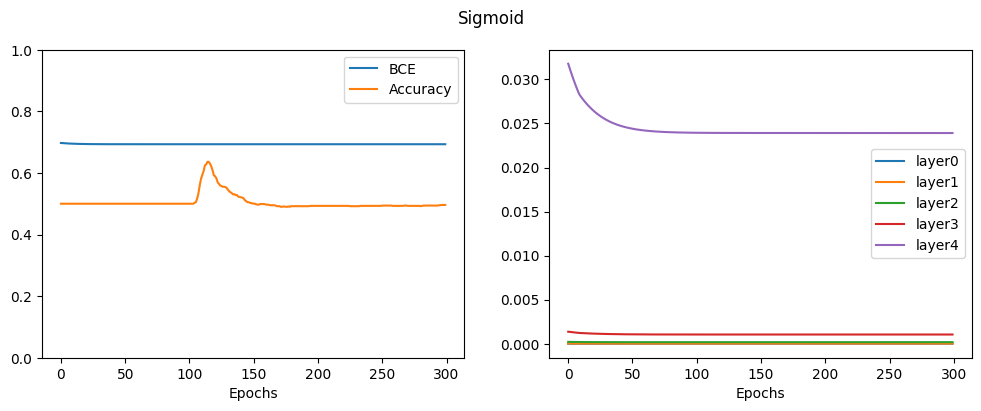

Tanh
Epoch 50: BCE=0.6900, Acc=50.00%
Epoch 100: BCE=0.6568, Acc=76.10%
Epoch 150: BCE=0.5310, Acc=79.40%
Epoch 200: BCE=0.4074, Acc=81.80%
Epoch 250: BCE=0.2550, Acc=90.80%
Epoch 300: BCE=0.1206, Acc=97.70%


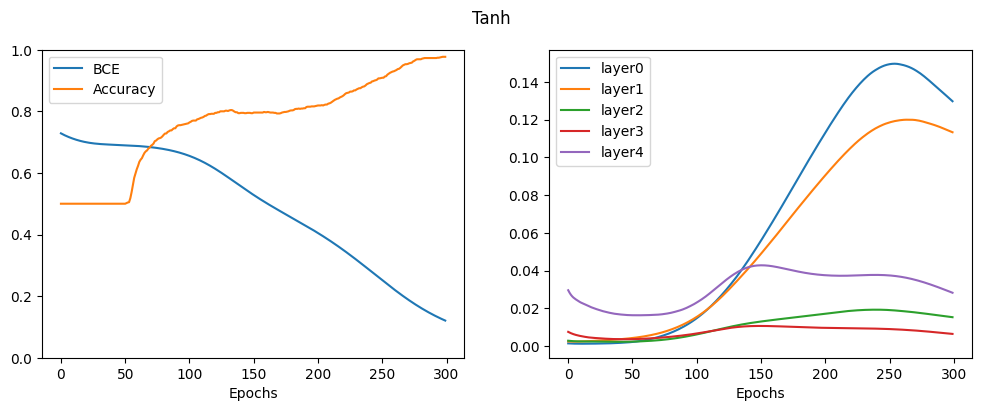

ReLU
Epoch 50: BCE=0.6958, Acc=50.00%
Epoch 100: BCE=0.6940, Acc=50.00%
Epoch 150: BCE=0.6934, Acc=50.00%
Epoch 200: BCE=0.6932, Acc=50.00%
Epoch 250: BCE=0.6932, Acc=50.00%
Epoch 300: BCE=0.6932, Acc=50.00%


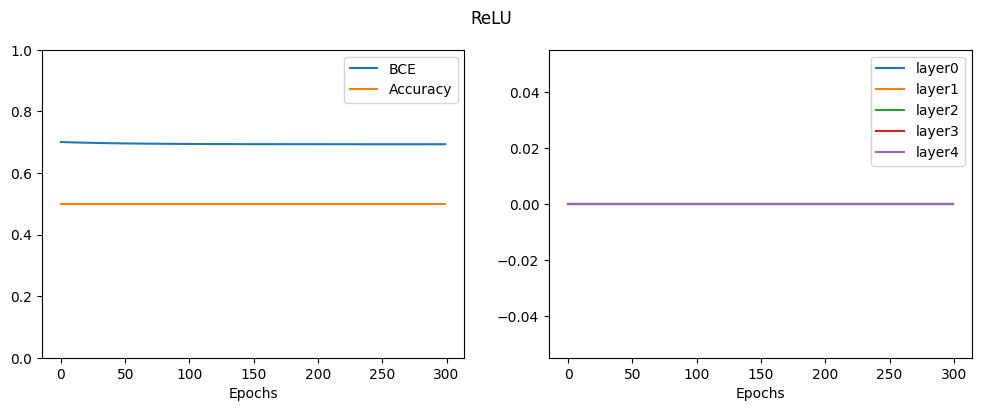

ReLU6
Epoch 50: BCE=0.6948, Acc=50.00%
Epoch 100: BCE=0.6884, Acc=50.00%
Epoch 150: BCE=0.6227, Acc=82.80%
Epoch 200: BCE=0.4256, Acc=98.10%
Epoch 250: BCE=0.2251, Acc=98.70%
Epoch 300: BCE=0.1186, Acc=98.70%


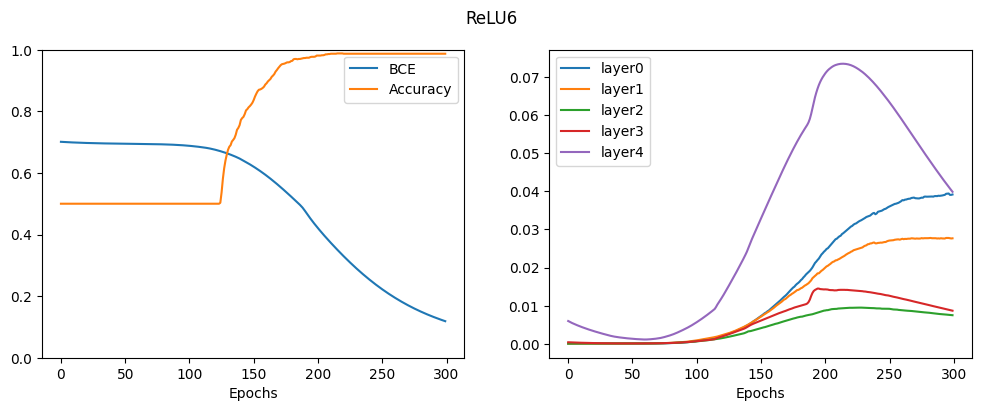

LeakyReLU
Epoch 50: BCE=0.6842, Acc=63.10%
Epoch 100: BCE=0.5990, Acc=85.00%
Epoch 150: BCE=0.3905, Acc=94.80%
Epoch 200: BCE=0.1899, Acc=98.90%
Epoch 250: BCE=0.0942, Acc=98.80%
Epoch 300: BCE=0.0553, Acc=98.90%


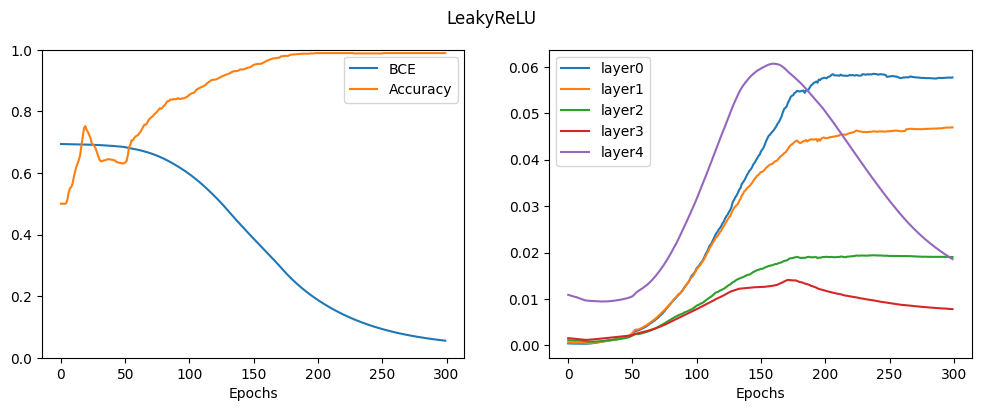

In [9]:
for activation in [nn.Sigmoid, nn.Tanh, nn.ReLU, nn.ReLU6, nn.LeakyReLU]:
    print(activation.__name__)
    m = CircleModel(activation=activation)
    bce_hist, acc_hist, grad_hist = train_circle(m, Xc, yc)

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(bce_hist, label="BCE")
    ax[0].plot(acc_hist, label="Accuracy")
    ax[0].set_ylim(0, 1)
    ax[0].set_xlabel("Epochs")
    for i, g in enumerate(grad_hist):
        ax[1].plot(g, label="layer" + str(i))
    ax[1].set_xlabel("Epochs")
    fig.suptitle(activation.__name__)
    ax[0].legend()
    ax[1].legend()
    plt.show()

## Chương 15 - Hàm mất mát

In [10]:
mae = nn.L1Loss()
mse = nn.MSELoss()
predict = torch.tensor([0., 3.])
target = torch.tensor([1., 0.])
print("MAE: %.3f" % mae(predict, target))
print("MSE: %.3f" % mse(predict, target))

MAE: 2.000
MSE: 5.000


In [11]:
ce = nn.CrossEntropyLoss()
logits = torch.tensor([[-1.90, -0.29, -2.30], [-0.29, -1.90, -2.30]])
onehot = torch.tensor([[0., 1., 0.], [1., 0., 0.]])
print("CE với one-hot: %.3f" % ce(logits, onehot))

idx = onehot.argmax(dim=1)
print(idx)
print("CE với chỉ số lớp: %.3f" % ce(logits, idx))

# LogSoftmax + NLLLoss cho kết quả giống hệt
nll = nn.NLLLoss()
print("NLL: %.3f" % nll(nn.LogSoftmax(dim=1)(logits), idx))

bce = nn.BCELoss()
print("BCE: %.3f" % bce(torch.tensor([0.75, 0.25]), torch.tensor([1., 0.])))

CE với one-hot: 0.288
tensor([1, 0])
CE với chỉ số lớp: 0.288
NLL: 0.288
BCE: 0.288


In [12]:
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()
Xh, yh = housing.data, housing.target
Xh_train_raw, Xh_test_raw, yh_train, yh_test = train_test_split(Xh, yh, train_size=0.7, shuffle=True)

scaler = StandardScaler().fit(Xh_train_raw)
Xh_train = torch.tensor(scaler.transform(Xh_train_raw), dtype=torch.float32)
Xh_test = torch.tensor(scaler.transform(Xh_test_raw), dtype=torch.float32)
yh_train = torch.tensor(yh_train, dtype=torch.float32).reshape(-1, 1)
yh_test = torch.tensor(yh_test, dtype=torch.float32).reshape(-1, 1)

In [13]:
def mape_loss(output, target):
    return torch.mean(torch.abs((target - output) / target))


def make_housing_model():
    return nn.Sequential(
        nn.Linear(8, 24), nn.ReLU(),
        nn.Linear(24, 12), nn.ReLU(),
        nn.Linear(12, 6), nn.ReLU(),
        nn.Linear(6, 1),
    )


model = make_housing_model()
optimizer = optim.Adam(model.parameters(), lr=0.0001)
n_epochs = 100
batch_size = 10
batch_start = torch.arange(0, len(Xh_train), batch_size)

best_mape = np.inf
best_weights = None
for epoch in range(n_epochs):
    model.train()
    for start in batch_start:
        xb = Xh_train[start:start + batch_size]
        yb = yh_train[start:start + batch_size]
        loss = mape_loss(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        mape = float(mape_loss(model(Xh_test), yh_test))
    if mape < best_mape:
        best_mape = mape
        best_weights = copy.deepcopy(model.state_dict())

model.load_state_dict(best_weights)
print("MAPE: %.2f" % best_mape)

model.eval()
with torch.no_grad():
    for i in range(5):
        s = torch.tensor(scaler.transform(Xh_test_raw[i:i + 1]), dtype=torch.float32)
        print(Xh_test_raw[i], "->", model(s)[0].numpy(), "(đúng:", yh_test[i].numpy(), ")")

MAPE: 0.19
[ 6.77410000e+00  9.00000000e+00  6.92206367e+00  1.05598244e+00
  2.58100000e+03  2.83315038e+00  3.79600000e+01 -1.22200000e+02] -> [3.1595433] (đúng: [3.107] )
[   4.4342       20.            5.31012658    0.97151899  840.
    2.65822785   34.96       -120.42      ] -> [2.2603364] (đúng: [1.607] )
[ 6.14000000e+00  2.80000000e+01  6.57553957e+00  1.07050360e+00
  1.69300000e+03  2.43597122e+00  3.41500000e+01 -1.18600000e+02] -> [3.41371] (đúng: [3.619] )
[ 2.91250000e+00  2.80000000e+01  3.74815906e+00  1.10751105e+00
  1.54800000e+03  2.27982327e+00  3.40200000e+01 -1.18490000e+02] -> [2.327421] (đúng: [4.75] )
[ 1.06868000e+01  3.00000000e+01  7.98621554e+00  1.07017544e+00
  2.14900000e+03  2.69298246e+00  3.74100000e+01 -1.22290000e+02] -> [5.616616] (đúng: [5.00001] )


## Chương 16 - Dropout (dữ liệu sonar)

In [14]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold

sonar = pd.read_csv("data/sonar.csv", header=None)
Xs = torch.tensor(sonar.iloc[:, 0:60].values, dtype=torch.float32)
ys = LabelEncoder().fit_transform(sonar.iloc[:, 60])
ys = torch.tensor(ys, dtype=torch.float32).reshape(-1, 1)
print(Xs.shape, ys.shape)

torch.Size([208, 60]) torch.Size([208, 1])


In [15]:
class SonarModel(nn.Module):
    # where: None | "input" | "hidden"
    def __init__(self, where=None, p=0.2):
        super().__init__()
        self.where = where
        self.drop = nn.Dropout(p)
        self.layer1 = nn.Linear(60, 60)
        self.act1 = nn.ReLU()
        self.layer2 = nn.Linear(60, 30)
        self.act2 = nn.ReLU()
        self.output = nn.Linear(30, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        if self.where == "input":
            x = self.drop(x)
        x = self.act1(self.layer1(x))
        if self.where == "hidden":
            x = self.drop(x)
        x = self.act2(self.layer2(x))
        if self.where == "hidden":
            x = self.drop(x)
        return self.sigmoid(self.output(x))


def model_train(model, X_train, y_train, X_val, y_val, n_epochs=300, batch_size=16):
    loss_fn = nn.BCELoss()
    optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.8)
    batch_start = torch.arange(0, len(X_train), batch_size)

    model.train()
    for epoch in range(n_epochs):
        for start in batch_start:
            xb = X_train[start:start + batch_size]
            yb = y_train[start:start + batch_size]
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        return float((model(X_val).round() == y_val).float().mean())


def cv_sonar(where):
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    accs = []
    for tr, te in kfold.split(Xs, ys):
        acc = model_train(SonarModel(where), Xs[tr], ys[tr], Xs[te], ys[te])
        accs.append(acc)
    print("%-8s %.2f%% (+/- %.2f%%)" % (where, np.mean(accs) * 100, np.std(accs) * 100))

In [16]:
cv_sonar(None)
cv_sonar("input")
cv_sonar("hidden")

None     84.10% (+/- 6.89%)
input    79.76% (+/- 9.12%)
hidden   84.17% (+/- 8.22%)


## Chương 17 - Lịch trình learning rate (dữ liệu ionosphere)

In [17]:
import torch.optim.lr_scheduler as lr_scheduler

iono = pd.read_csv("data/ionosphere.csv", header=None)
Xi = torch.tensor(iono.iloc[:, 0:34].values.astype(float), dtype=torch.float32)
yi = torch.tensor(LabelEncoder().fit_transform(iono.iloc[:, 34]), dtype=torch.float32).reshape(-1, 1)
Xi_train, Xi_test, yi_train, yi_test = train_test_split(Xi, yi, train_size=0.7, shuffle=True)


def run_iono(make_scheduler=None, verbose=True):
    model = nn.Sequential(nn.Linear(34, 34), nn.ReLU(), nn.Linear(34, 1), nn.Sigmoid())
    loss_fn = nn.BCELoss()
    optimizer = optim.SGD(model.parameters(), lr=0.1)
    scheduler = make_scheduler(optimizer) if make_scheduler else None
    batch_size = 24
    batch_start = torch.arange(0, len(Xi_train), batch_size)

    lrs = []
    model.train()
    for epoch in range(50):
        for start in batch_start:
            xb = Xi_train[start:start + batch_size]
            yb = yi_train[start:start + batch_size]
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        before = optimizer.param_groups[0]["lr"]
        if scheduler:
            scheduler.step()
        lrs.append((before, optimizer.param_groups[0]["lr"]))

    model.eval()
    with torch.no_grad():
        acc = float((model(Xi_test).round() == yi_test).float().mean())
    if verbose:
        for e in (0, 1, 2, 29, 49):
            print("Epoch %d: lr %.4f -> %.4f" % (e, *lrs[e]))
        print("Accuracy: %.2f%%" % (acc * 100))
    return lrs

In [18]:
print("lr cố định")
_ = run_iono()

lr cố định
Epoch 0: lr 0.1000 -> 0.1000
Epoch 1: lr 0.1000 -> 0.1000
Epoch 2: lr 0.1000 -> 0.1000
Epoch 29: lr 0.1000 -> 0.1000
Epoch 49: lr 0.1000 -> 0.1000
Accuracy: 88.68%


In [19]:
print("LinearLR")
_ = run_iono(lambda o: lr_scheduler.LinearLR(o, start_factor=1.0, end_factor=0.5, total_iters=30))

LinearLR
Epoch 0: lr 0.1000 -> 0.0983
Epoch 1: lr 0.0983 -> 0.0967
Epoch 2: lr 0.0967 -> 0.0950
Epoch 29: lr 0.0517 -> 0.0500
Epoch 49: lr 0.0500 -> 0.0500
Accuracy: 88.68%


In [20]:
print("ExponentialLR")
_ = run_iono(lambda o: lr_scheduler.ExponentialLR(o, gamma=0.99))

ExponentialLR
Epoch 0: lr 0.1000 -> 0.0990
Epoch 1: lr 0.0990 -> 0.0980
Epoch 2: lr 0.0980 -> 0.0970
Epoch 29: lr 0.0747 -> 0.0740
Epoch 49: lr 0.0611 -> 0.0605
Accuracy: 89.62%


In [21]:
def lr_lambda(epoch):
    base_lr = 0.1
    factor = 0.01
    return base_lr / (1 + factor * epoch)


print("LambdaLR")
_ = run_iono(lambda o: lr_scheduler.LambdaLR(o, lr_lambda))

LambdaLR
Epoch 0: lr 0.0100 -> 0.0099
Epoch 1: lr 0.0099 -> 0.0098
Epoch 2: lr 0.0098 -> 0.0097
Epoch 29: lr 0.0078 -> 0.0077
Epoch 49: lr 0.0067 -> 0.0067
Accuracy: 69.81%


## Chương 18 - DataLoader và Dataset

In [22]:
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split, default_collate

Xs_np = sonar.iloc[:, 0:60].values
ys_np = LabelEncoder().fit_transform(sonar.iloc[:, 60])
Xs_all = torch.tensor(Xs_np, dtype=torch.float32)
ys_all = torch.tensor(ys_np, dtype=torch.float32).reshape(-1, 1)

loader = DataLoader(list(zip(Xs_all, ys_all)), shuffle=True, batch_size=16)
xb, yb = next(iter(loader))
print(xb.shape, yb.shape)

torch.Size([16, 60]) torch.Size([16, 1])


In [23]:
def train_sonar_loader(loader, X_test, y_test, n_epochs=200):
    model = nn.Sequential(
        nn.Linear(60, 60), nn.ReLU(),
        nn.Linear(60, 30), nn.ReLU(),
        nn.Linear(30, 1), nn.Sigmoid(),
    )
    loss_fn = nn.BCELoss()
    optimizer = optim.SGD(model.parameters(), lr=0.1)
    model.train()
    for epoch in range(n_epochs):
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        acc = float((model(X_test).round() == y_test).float().mean())
    print("Model accuracy: %.2f%%" % (acc * 100))


Xa_train, Xa_test, ya_train, ya_test = train_test_split(Xs_all, ys_all, train_size=0.7, shuffle=True)
train_sonar_loader(DataLoader(list(zip(Xa_train, ya_train)), shuffle=True, batch_size=16), Xa_test, ya_test)

Model accuracy: 88.89%


In [24]:
class SonarDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


dataset = SonarDataset(Xs_np, ys_np.reshape(-1, 1))
trainset, testset = random_split(dataset, [0.7, 0.3])
X_t, y_t = default_collate(testset)
train_sonar_loader(DataLoader(trainset, shuffle=True, batch_size=16), X_t, y_t)

Model accuracy: 88.71%


## Chương 19 - skorch và scikit-learn (sonar)

In [25]:
from skorch import NeuralNetBinaryClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV

X_sk = Xs_all
y_sk = torch.tensor(ys_np, dtype=torch.float32)


class SonarClassifier(nn.Module):
    def __init__(self, n_layers=3):
        super().__init__()
        self.layers = []
        self.acts = []
        for i in range(n_layers):
            self.layers.append(nn.Linear(60, 60))
            self.acts.append(nn.ReLU())
            self.add_module(f"layer{i}", self.layers[-1])
            self.add_module(f"act{i}", self.acts[-1])
        self.output = nn.Linear(60, 1)

    def forward(self, x):
        for layer, act in zip(self.layers, self.acts):
            x = act(layer(x))
        return self.output(x)


net = NeuralNetBinaryClassifier(
    SonarClassifier,
    criterion=torch.nn.BCEWithLogitsLoss,
    optimizer=torch.optim.Adam,
    lr=0.0001,
    max_epochs=150,
    batch_size=10,
)
net.fit(X_sk, y_sk)

  epoch    train_loss    valid_acc    valid_loss     dur
-------  ------------  -----------  ------------  ------
      1        0.6932       0.5238        0.6912  0.0467
      2        0.6909       0.5238        0.6911  0.0415
      3        0.6905       0.5238        0.6911  0.0487
      4        0.6903       0.5238        0.6910  0.0478
      5        0.6900       0.5238        0.6910  0.0494
      6        0.6898       0.5238        0.6910  0.0455
      7        0.6896       0.5238        0.6910  0.0474
      8        0.6894       0.5238        0.6909  0.0471
      9        0.6891       0.5238        0.6909  0.0475
     10        0.6889       0.5238        0.6909  0.0504
     11        0.6886       0.5238        0.6909  0.0478
     12        0.6884       0.5238        0.6908  0.0500
     13        0.6881       0.5238        0.6908  0.0446
     14        0.6878       0.5238        0.6907  0.0436
     15        0.6875       0.5238        0.6907  0.0482
     16        0.6872       0.5

,module,<class '__mai...arClassifier'>
,criterion,<class 'torch...thLogitsLoss'>
,train_split,<skorch.datas...002AE7DA20910>
,threshold,0.5
,optimizer,<class 'torch...im.adam.Adam'>
,lr,0.0001
,max_epochs,150
,batch_size,10
,iterator_train,<class 'torch...r.DataLoader'>
,iterator_valid,<class 'torch...r.DataLoader'>
,dataset,<class 'skorc...aset.Dataset'>


In [26]:
net = NeuralNetBinaryClassifier(
    SonarClassifier,
    criterion=torch.nn.BCEWithLogitsLoss,
    optimizer=torch.optim.Adam,
    lr=0.0001,
    max_epochs=150,
    batch_size=10,
    verbose=False,
)
kfold = StratifiedKFold(n_splits=5, shuffle=True)
results = cross_val_score(net, X_sk, y_sk, cv=kfold)
print(results)
print("mean = %.3f; std = %.3f" % (results.mean(), results.std()))

[0.76190476 0.71428571 0.78571429 0.68292683 0.7804878 ]
mean = 0.745; std = 0.040


In [27]:
param_grid = {
    "module__n_layers": [1, 3, 5],
    "lr": [0.1, 0.01, 0.001, 0.0001],
    "max_epochs": [100, 150],
}
grid = GridSearchCV(net, param_grid, scoring="accuracy", verbose=1, cv=3)
result = grid.fit(X_sk, y_sk)

print("Best: %f using %s" % (result.best_score_, result.best_params_))
for mean, std, p in zip(result.cv_results_["mean_test_score"],
                        result.cv_results_["std_test_score"],
                        result.cv_results_["params"]):
    print("%f (%f) with: %r" % (mean, std, p))

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best: 0.659006 using {'lr': 0.01, 'max_epochs': 150, 'module__n_layers': 1}
0.533678 (0.003611) with: {'lr': 0.1, 'max_epochs': 100, 'module__n_layers': 1}
0.533678 (0.003611) with: {'lr': 0.1, 'max_epochs': 100, 'module__n_layers': 3}
0.533678 (0.003611) with: {'lr': 0.1, 'max_epochs': 100, 'module__n_layers': 5}
0.533678 (0.003611) with: {'lr': 0.1, 'max_epochs': 150, 'module__n_layers': 1}
0.533678 (0.003611) with: {'lr': 0.1, 'max_epochs': 150, 'module__n_layers': 3}
0.533678 (0.003611) with: {'lr': 0.1, 'max_epochs': 150, 'module__n_layers': 5}
0.605866 (0.066625) with: {'lr': 0.01, 'max_epochs': 100, 'module__n_layers': 1}
0.524155 (0.017080) with: {'lr': 0.01, 'max_epochs': 100, 'module__n_layers': 3}
0.572326 (0.056548) with: {'lr': 0.01, 'max_epochs': 100, 'module__n_layers': 5}
0.659006 (0.056973) with: {'lr': 0.01, 'max_epochs': 150, 'module__n_layers': 1}
0.591649 (0.083847) with: {'lr': 0.01, 'max_epochs': 150, '

In [28]:
from sklearn.pipeline import Pipeline, FunctionTransformer

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("float32", FunctionTransformer(func=lambda X: torch.tensor(X, dtype=torch.float32), validate=False)),
    ("sonarmodel", net.initialize()),
])

param_grid = {
    "sonarmodel__module__n_layers": [1, 3, 5],
    "sonarmodel__lr": [0.1, 0.01, 0.001, 0.0001],
    "sonarmodel__max_epochs": [100, 150],
}
grid = GridSearchCV(pipe, param_grid, scoring="accuracy", verbose=1, cv=3)
result = grid.fit(X_sk, y_sk)
print("Best: %f using %s" % (result.best_score_, result.best_params_))

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best: 0.591787 using {'sonarmodel__lr': 0.001, 'sonarmodel__max_epochs': 150, 'sonarmodel__module__n_layers': 5}


## Chương 20 - Tinh chỉnh siêu tham số (Pima diabetes)

Sách dùng `NeuralNetClassifier` với `BCELoss`. Ở đây dùng `NeuralNetBinaryClassifier` với logits nên không cần sigmoid ở cuối model,
vì bản skorch mới đòi nhãn 1 chiều.

In [29]:
pima = np.loadtxt("data/pima-indians-diabetes.csv", delimiter=",")
Xp = torch.tensor(pima[:, 0:8], dtype=torch.float32)
yp = torch.tensor(pima[:, 8], dtype=torch.float32)


class PimaClassifier(nn.Module):
    def __init__(self, activation=nn.ReLU, dropout_rate=0.0, neurons=12, init_mode="default"):
        super().__init__()
        self.layer = nn.Linear(8, neurons)
        self.act = activation()
        self.drop = nn.Dropout(dropout_rate)
        self.output = nn.Linear(neurons, 1)
        if init_mode != "default":
            init = getattr(nn.init, init_mode)
            init(self.layer.weight)
            init(self.output.weight)

    def forward(self, x):
        x = self.drop(self.act(self.layer(x)))
        return self.output(x)


def make_net(**kw):
    base = dict(max_epochs=100, batch_size=10, optimizer=optim.Adam, verbose=False, train_split=None)
    base.update(kw)
    return NeuralNetBinaryClassifier(PimaClassifier, **base)


def search(param_grid, **kw):
    g = GridSearchCV(make_net(**kw), param_grid, cv=3, n_jobs=1)
    r = g.fit(Xp, yp)
    print("Best: %f using %s" % (r.best_score_, r.best_params_))
    for m, s, p in zip(r.cv_results_["mean_test_score"], r.cv_results_["std_test_score"], r.cv_results_["params"]):
        print("  %f (%f) with: %r" % (m, s, p))
    return r

In [30]:
_ = search({"batch_size": [10, 20, 40, 60, 80, 100], "max_epochs": [10, 50, 100]})

Best: 0.729167 using {'batch_size': 20, 'max_epochs': 100}
  0.670573 (0.019488) with: {'batch_size': 10, 'max_epochs': 10}
  0.692708 (0.016053) with: {'batch_size': 10, 'max_epochs': 50}
  0.707031 (0.028705) with: {'batch_size': 10, 'max_epochs': 100}
  0.669271 (0.015733) with: {'batch_size': 20, 'max_epochs': 10}
  0.716146 (0.028940) with: {'batch_size': 20, 'max_epochs': 50}
  0.729167 (0.020752) with: {'batch_size': 20, 'max_epochs': 100}
  0.661458 (0.006639) with: {'batch_size': 40, 'max_epochs': 10}
  0.696615 (0.025780) with: {'batch_size': 40, 'max_epochs': 50}
  0.729167 (0.021710) with: {'batch_size': 40, 'max_epochs': 100}
  0.675781 (0.008438) with: {'batch_size': 60, 'max_epochs': 10}
  0.701823 (0.020505) with: {'batch_size': 60, 'max_epochs': 50}
  0.716146 (0.025582) with: {'batch_size': 60, 'max_epochs': 100}
  0.662760 (0.017566) with: {'batch_size': 80, 'max_epochs': 10}
  0.710938 (0.015947) with: {'batch_size': 80, 'max_epochs': 50}
  0.701823 (0.017566) with:

In [ ]:
_ = search({"optimizer": [optim.SGD, optim.RMSprop, optim.Adagrad, optim.Adadelta,
                          optim.Adam, optim.Adamax, optim.NAdam]})

In [ ]:
_ = search({"lr": [0.001, 0.01, 0.1, 0.2, 0.3], "optimizer__momentum": [0.0, 0.2, 0.4, 0.6, 0.8, 0.9]},
           optimizer=optim.SGD)

In [ ]:
_ = search({"module__init_mode": ["default", "uniform_", "normal_", "xavier_uniform_", "xavier_normal_",
                                  "kaiming_uniform_", "kaiming_normal_"]})

In [ ]:
_ = search({"module__activation": [nn.Softmax, nn.Softplus, nn.Softsign, nn.ReLU, nn.Tanh, nn.Sigmoid, nn.Hardsigmoid]})

In [ ]:
_ = search({"module__dropout_rate": [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]})

In [ ]:
_ = search({"module__neurons": [1, 5, 10, 15, 20, 25, 30]})

## Chương 21 - Checkpoint và early stopping

Sách lấy dữ liệu `electricity` từ OpenML. Ở đây dùng lại Pima (cũng 8 đặc trưng) cho khỏi tải thêm.

In [ ]:
pima_ds = TensorDataset(Xp, yp.reshape(-1, 1))
trainset, testset = random_split(pima_ds, [0.7, 0.3])
X_te, y_te = default_collate(testset)


def make_pima_seq():
    return nn.Sequential(
        nn.Linear(8, 12), nn.ReLU(),
        nn.Linear(12, 12), nn.ReLU(),
        nn.Linear(12, 1), nn.Sigmoid(),
    )


def checkpoint(model, optimizer, filename):
    torch.save({"optimizer": optimizer.state_dict(), "model": model.state_dict()}, filename)


def resume(model, optimizer, filename):
    ck = torch.load(filename)
    model.load_state_dict(ck["model"])
    optimizer.load_state_dict(ck["optimizer"])

In [ ]:
def fit(model, optimizer, start_epoch, end_epoch):
    loader = DataLoader(trainset, shuffle=True, batch_size=32)
    loss_fn = nn.BCELoss()
    for epoch in range(start_epoch, end_epoch):
        model.train()
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            acc = float((model(X_te).round() == y_te).float().mean()) * 100
        print(f"End of epoch {epoch}: accuracy = {acc:.2f}%")
        checkpoint(model, optimizer, f"out/epoch-{epoch}.pth")


model = make_pima_seq()
optimizer = optim.SGD(model.parameters(), lr=0.1)
fit(model, optimizer, 0, 10)

In [ ]:
# giả sử bị ngắt sau epoch 9, nạp lại và train tiếp từ epoch 10
model = make_pima_seq()
optimizer = optim.SGD(model.parameters(), lr=0.1)
resume(model, optimizer, "out/epoch-9.pth")
fit(model, optimizer, 10, 15)

In [ ]:
model = make_pima_seq()
optimizer = optim.SGD(model.parameters(), lr=0.1)
loader = DataLoader(trainset, shuffle=True, batch_size=32)
loss_fn = nn.BCELoss()

n_epochs = 10000
early_stop_thresh = 5
best_accuracy = -1
best_epoch = -1

for epoch in range(n_epochs):
    model.train()
    for xb, yb in loader:
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        acc = float((model(X_te).round() == y_te).float().mean()) * 100
    print(f"End of epoch {epoch}: accuracy = {acc:.2f}%")

    if acc > best_accuracy:
        best_accuracy = acc
        best_epoch = epoch
        checkpoint(model, optimizer, "out/best_model.pth")
    elif epoch - best_epoch > early_stop_thresh:
        print("Early stopped training at epoch %d" % epoch)
        break

resume(model, optimizer, "out/best_model.pth")
print("best epoch:", best_epoch, "acc:", best_accuracy)

## Chương 22 - Xuất model sang ONNX để xem bằng Netron

In [ ]:
class IrisModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(4, 8)
        self.act = nn.ReLU()
        self.output = nn.Linear(8, 3)

    def forward(self, x):
        return self.output(self.act(self.hidden(x)))


model = IrisModel()
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
batch_size = 10
batch_start = torch.arange(0, len(X_train), batch_size)

for epoch in range(100):
    for start in batch_start:
        xb = X_train[start:start + batch_size]
        yb = y_train[start:start + batch_size]
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

with torch.no_grad():
    print("Model accuracy: %.2f%%" % (float((model(X_test).argmax(1) == y_test).float().mean()) * 100))

In [ ]:
try:
    torch.onnx.export(model, X_test, "out/iris.onnx",
                      input_names=["features"], output_names=["logits"], dynamo=False)
    print("đã tạo out/iris.onnx, mở bằng Netron để xem")
except Exception as e:
    print("không xuất được ONNX:", type(e).__name__, e)

## Chương 23 - Thu thập metric trong vòng huấn luyện

In [ ]:
model = make_housing_model()
loss_fn = nn.MSELoss()
mae_fn = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

n_epochs = 100
batch_size = 32
batch_start = torch.arange(0, len(Xh_train), batch_size)

train_mse_history = []
test_mse_history = []
test_mae_history = []

for epoch in range(n_epochs):
    model.train()
    epoch_mse = []
    for start in batch_start:
        xb = Xh_train[start:start + batch_size]
        yb = yh_train[start:start + batch_size]
        loss = loss_fn(model(xb), yb)
        epoch_mse.append(float(loss))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    train_mse_history.append(sum(epoch_mse) / len(epoch_mse))

    model.eval()
    with torch.no_grad():
        pred = model(Xh_test)
        test_mse_history.append(float(loss_fn(pred, yh_test)))
        test_mae_history.append(float(mae_fn(pred, yh_test)))

print("train RMSE %.3f | test RMSE %.3f | test MAE %.3f" % (
    np.sqrt(train_mse_history[-1]), np.sqrt(test_mse_history[-1]), test_mae_history[-1]))

In [ ]:
plt.plot(np.sqrt(train_mse_history), label="Train RMSE")
plt.plot(np.sqrt(test_mse_history), label="Test RMSE")
plt.plot(test_mae_history, label="Test MAE")
plt.xlabel("epochs")
plt.legend()
plt.show()